<a href="https://colab.research.google.com/github/spicy-peppers84/spicy-peppers84.github.io/blob/main/Oct21_Activity4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, roc_curve, roc_auc_score, classification_report
)

DATA_URL = (
    "https://raw.githubusercontent.com/yongmeiwang/"
    "AI_BigData_CancerBiology/main/Data/gtex_integrin_7_organs.xlsx"
)

data = pd.read_excel(DATA_URL)

print(f"Rows: {data.shape[0]:,} | Columns: {data.shape[1]:,}")
display(data.head())
print("\nColumns:")
print(data.columns.tolist())

Rows: 1,987 | Columns: 29


,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050



Columns:
['Unnamed: 0', 'primary_site', 'ITGA10', 'ITGAD', 'ITGAM', 'ITGA3', 'ITGBL1', 'ITGAE', 'ITGA2', 'ITGB3', 'ITGA7', 'ITGB8', 'ITGAX', 'ITGAV', 'ITGB6', 'ITGB7', 'ITGA5', 'ITGB4', 'ITGB2', 'ITGA6', 'ITGA2B', 'ITGB1', 'ITGAL', 'ITGA9', 'ITGB5', 'ITGA8', 'ITGA4', 'ITGA1', 'ITGA11']


In [3]:
target_col = "primary_site"
selected_sites = ["Brain", "Lung"]

subset = data.loc[data[target_col].isin(selected_sites)].copy()
print("Subset dimensions:", subset.shape)
display(subset[target_col].value_counts().rename_axis("Tissue").to_frame("Samples"))

integrin_cols = [col for col in subset.columns if col.startswith("ITG")]
print(f"Integrin features found: {len(integrin_cols)}")
print("Missing values in target:", subset[target_col].isna().sum())
print("Missing values across integrin features:", int(subset[integrin_cols].isna().sum().sum()))

Subset dimensions: (1440, 29)


,Samples
Tissue,
Brain,1152
Lung,288


Integrin features found: 27
Missing values in target: 0
Missing values across integrin features: 0


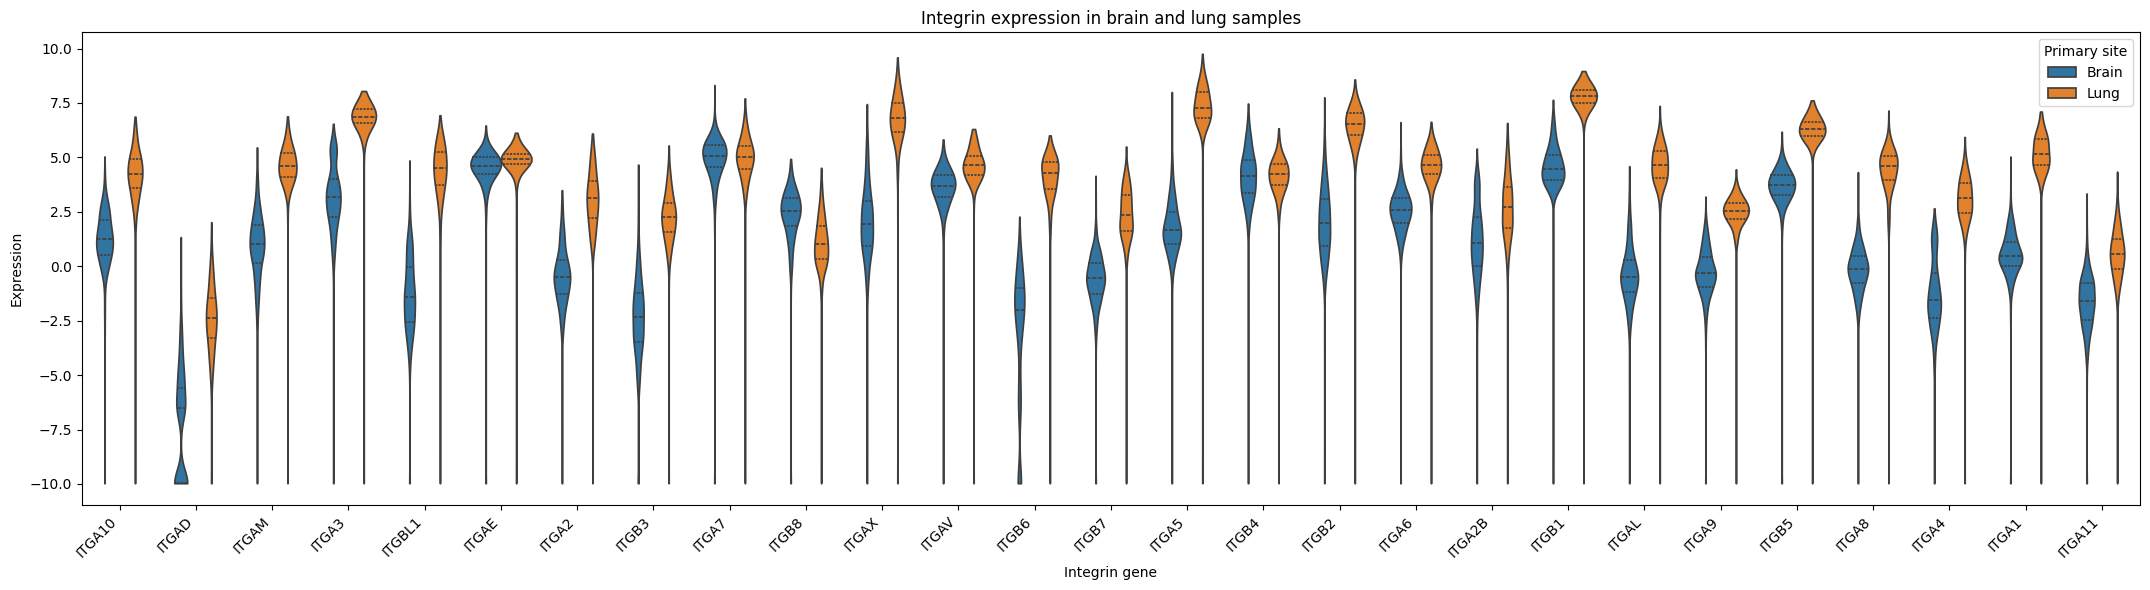

In [4]:
plot_data = subset.melt(
    id_vars=target_col,
    value_vars=integrin_cols,
    var_name="Gene",
    value_name="Expression"
)

plt.figure(figsize=(max(12, len(integrin_cols) * 0.8), 6))
sns.violinplot(
    data=plot_data,
    x="Gene",
    y="Expression",
    hue=target_col,
    inner="quartile",
    cut=0
)
plt.title("Integrin expression in brain and lung samples")
plt.xlabel("Integrin gene")
plt.ylabel("Expression")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Primary site")
plt.tight_layout()
plt.show()

In [5]:
candidate_features = ["ITGA10", "ITGAV", "ITGAE"]
required_cols = [target_col] + candidate_features
model_data = subset[required_cols].dropna().copy()

X_train_idx, X_test_idx = train_test_split(
    model_data.index,
    test_size=0.30,
    random_state=42,
    stratify=model_data[target_col]
)

y_train = model_data.loc[X_train_idx, target_col]
y_test = model_data.loc[X_test_idx, target_col]

feature_sets = {
    "ITGA10": ["ITGA10"],
    "ITGAV": ["ITGAV"],
    "ITGAE": ["ITGAE"],
    "ITGAE + ITGAV": ["ITGAE", "ITGAV"],
}

fitted_models = {}
roc_details = {}
summary_rows = []

for label, features in feature_sets.items():
    X_train = model_data.loc[X_train_idx, features]
    X_test = model_data.loc[X_test_idx, features]

    classifier = LogisticRegression(max_iter=2000)
    classifier.fit(X_train, y_train)

    predictions = classifier.predict(X_test)
    lung_position = list(classifier.classes_).index("Lung")
    lung_probability = classifier.predict_proba(X_test)[:, lung_position]

    y_test_binary = (y_test == "Lung").astype(int)
    fpr, tpr, thresholds = roc_curve(y_test_binary, lung_probability)
    auc_value = roc_auc_score(y_test_binary, lung_probability)

    fitted_models[label] = classifier
    roc_details[label] = {
        "fpr": fpr, "tpr": tpr, "thresholds": thresholds,
        "auc": auc_value, "features": features,
        "probability": lung_probability
    }
    summary_rows.append({
        "Model": label,
        "Features": ", ".join(features),
        "Accuracy": accuracy_score(y_test, predictions),
        "ROC AUC": auc_value
    })

model_summary = pd.DataFrame(summary_rows).sort_values("ROC AUC", ascending=False)
display(model_summary.round(4))

,Model,Features,Accuracy,ROC AUC
0,ITGA10,ITGA10,0.9421,0.9734
1,ITGAV,ITGAV,0.8287,0.8442
3,ITGAE + ITGAV,"ITGAE, ITGAV",0.8264,0.8398
2,ITGAE,ITGAE,0.8009,0.6904


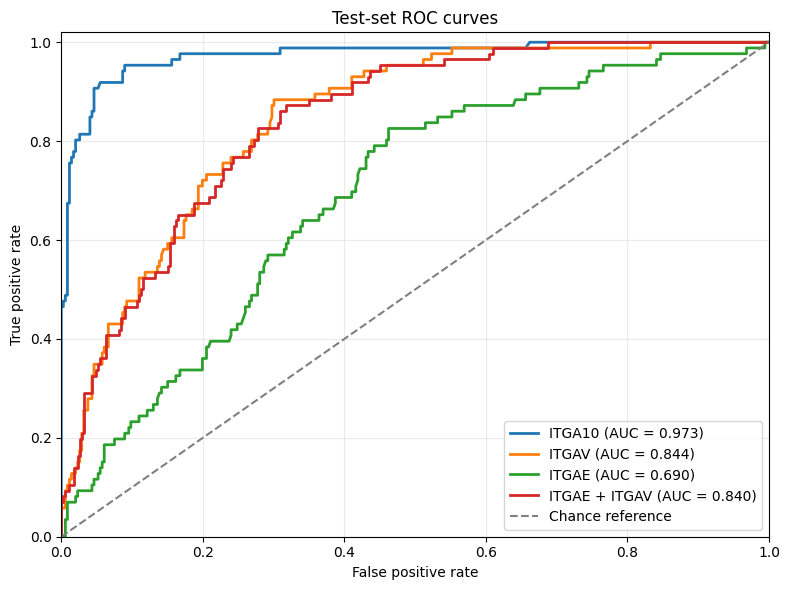

In [6]:
plt.figure(figsize=(8, 6))
for label, result in roc_details.items():
    plt.plot(
        result["fpr"], result["tpr"],
        linewidth=2,
        label=f"{label} (AUC = {result['auc']:.3f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance reference")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Test-set ROC curves")
plt.xlim(0, 1)
plt.ylim(0, 1.02)
plt.legend(loc="lower right")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

Intercept: -8.8231
ITGAV coefficient: 1.7809
Estimated 0.5-probability boundary: 4.9542


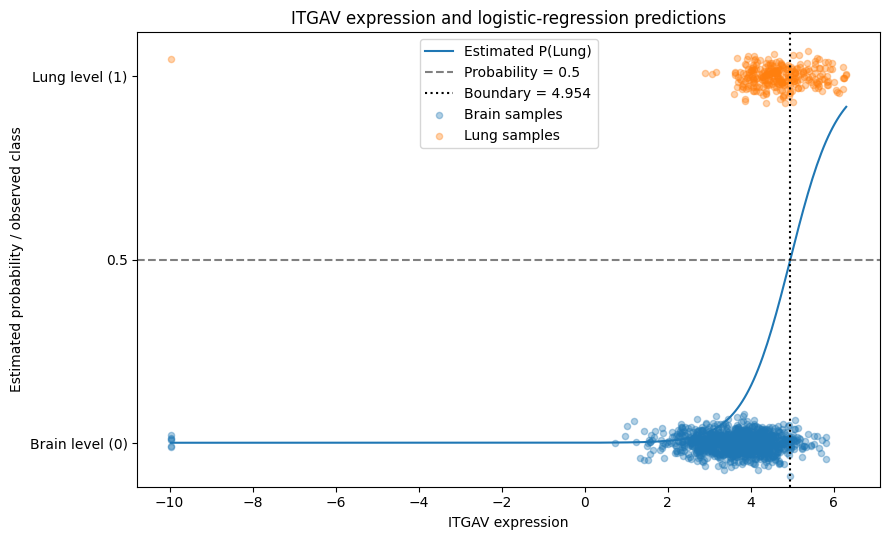

In [7]:
gene = "ITGAV"
model = fitted_models[gene]
intercept = float(model.intercept_[0])
slope = float(model.coef_[0][0])

x_values = np.linspace(model_data[gene].min(), model_data[gene].max(), 300)
lung_class_index = list(model.classes_).index("Lung")

from scipy.special import expit
linear_score = intercept + slope * x_values
if model.classes_[lung_class_index] == "Lung" and lung_class_index == 1:
    lung_probability_curve = expit(linear_score)
else:
    lung_probability_curve = 1 - expit(linear_score)

boundary = -intercept / slope if slope != 0 else np.nan
print(f"Intercept: {intercept:.4f}")
print(f"ITGAV coefficient: {slope:.4f}")
print(f"Estimated 0.5-probability boundary: {boundary:.4f}")

plt.figure(figsize=(9, 5.5))
plt.plot(x_values, lung_probability_curve, label="Estimated P(Lung)")
plt.axhline(0.5, linestyle="--", color="gray", label="Probability = 0.5")
if np.isfinite(boundary):
    plt.axvline(boundary, linestyle=":", color="black", label=f"Boundary = {boundary:.3f}")

brain_values = model_data.loc[model_data[target_col] == "Brain", gene]
lung_values = model_data.loc[model_data[target_col] == "Lung", gene]
rng = np.random.default_rng(42)
plt.scatter(brain_values, rng.normal(0, 0.025, len(brain_values)),
            alpha=0.35, s=20, label="Brain samples")
plt.scatter(lung_values, rng.normal(1, 0.025, len(lung_values)),
            alpha=0.35, s=20, label="Lung samples")
plt.xlabel("ITGAV expression")
plt.ylabel("Estimated probability / observed class")
plt.title("ITGAV expression and logistic-regression predictions")
plt.yticks([0, 0.5, 1], ["Brain level (0)", "0.5", "Lung level (1)"])
plt.ylim(-0.12, 1.12)
plt.legend()
plt.tight_layout()
plt.show()

In [8]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
X_cv = model_data[["ITGA10"]]
y_cv = (model_data[target_col] == "Lung").astype(int)

cv_auc = cross_val_score(
    LogisticRegression(max_iter=2000),
    X_cv,
    y_cv,
    cv=cv,
    scoring="roc_auc"
)

print("Fold AUC values:", np.round(cv_auc, 4))
print(f"Mean AUC: {cv_auc.mean():.4f}")
print(f"Standard deviation: {cv_auc.std():.4f}")

Fold AUC values: [0.9576 0.9846 0.9568 0.9729 0.9657]
Mean AUC: 0.9675
Standard deviation: 0.0103


Random forest accuracy: 0.9977
Random forest ROC AUC: 0.9999


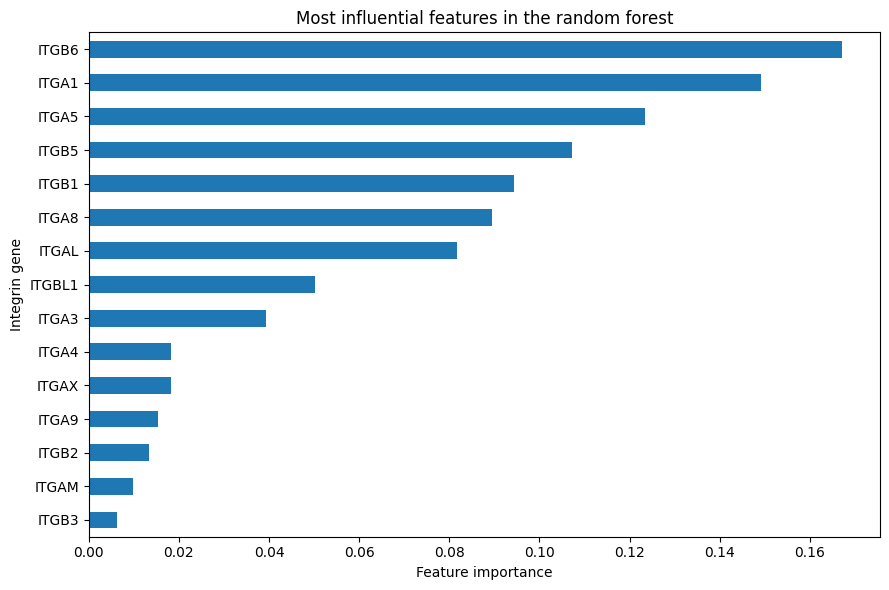

In [9]:
rf_data = subset[[target_col] + integrin_cols].dropna().copy()
rf_train_idx, rf_test_idx = train_test_split(
    rf_data.index,
    test_size=0.30,
    random_state=42,
    stratify=rf_data[target_col]
)

X_rf_train = rf_data.loc[rf_train_idx, integrin_cols]
X_rf_test = rf_data.loc[rf_test_idx, integrin_cols]
y_rf_train = rf_data.loc[rf_train_idx, target_col]
y_rf_test = rf_data.loc[rf_test_idx, target_col]

forest = RandomForestClassifier(n_estimators=300, random_state=42)
forest.fit(X_rf_train, y_rf_train)
rf_predictions = forest.predict(X_rf_test)
rf_lung_index = list(forest.classes_).index("Lung")
rf_lung_probability = forest.predict_proba(X_rf_test)[:, rf_lung_index]
rf_auc = roc_auc_score((y_rf_test == "Lung").astype(int), rf_lung_probability)

print(f"Random forest accuracy: {accuracy_score(y_rf_test, rf_predictions):.4f}")
print(f"Random forest ROC AUC: {rf_auc:.4f}")

importance = pd.Series(forest.feature_importances_, index=integrin_cols)
importance = importance.sort_values(ascending=False).head(15)

plt.figure(figsize=(9, 6))
importance.sort_values().plot(kind="barh")
plt.xlabel("Feature importance")
plt.ylabel("Integrin gene")
plt.title("Most influential features in the random forest")
plt.tight_layout()
plt.show()